# PoC · Asistente de apoyo al psicodiagnóstico (LC-B + LC-C)
**Kit PoC · Colab + LangChain + OpenRouter** · Etapa 1: entrada de texto

Flujo: el texto se **anonimiza** (NER local; nombres, lugares y organizaciones no salen de la VM) →
**guardrail** de contexto clínico (`respan/span-01-lite:free`) → **extraer** síntomas →
**agente CIE-11** (MCP en Azure) → **reporte** Markdown con código y liga OMS.

1. Abre este cuaderno en Colab y monta Google Drive cuando lo pida (la carpeta `poc_psicodiagnostico` debe estar en tu Drive).
2. Guarda `OPENROUTER_API_KEY` en los Secretos de Colab (acceso del notebook activado) o, en local, en el archivo `.env`.
3. Ejecuta todo. Una corrida completa usa cerca de 8 llamadas al modelo; la cuenta gratuita permite 50 por día.

> Trabaja solo con datos sintéticos o anonimizados: el endpoint gratuito del modelo registra el uso.

## 0 · Instalación, Drive y clave (no editar)

In [ ]:
# 0.1 · Dependencias (no editar). En Colab se instalan aquí; en local vienen de uv sync (ver README)
import subprocess
import sys

if "google.colab" in sys.modules:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-qU",
        "langchain>=1.4,<2", "langchain-openai>=1.6,<2", "langgraph>=1.2,<2",
        "langchain-mcp-adapters", "transformers", "torch", "pydantic", "requests", "pandas",
    ])
else:
    print("Entorno local: las dependencias vienen de uv sync (ver README).")

Entorno local: las dependencias vienen de uv sync (ver README).


In [ ]:
# 0.2 · Drive y ruta del paquete poc_psico (no editar)
import os
import sys

RUTA_PROYECTO = "/content/drive/MyDrive/LLM solutions architect/Módulo 5/poc_psicodiagnostico"
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception:
    RUTA_PROYECTO = os.getcwd()
sys.path.insert(0, RUTA_PROYECTO)
from poc_psico import grafo  # falla aquí si la ruta no es correcta
print("Paquete cargado desde", RUTA_PROYECTO)

Paquete cargado desde /Users/dalia/Library/CloudStorage/GoogleDrive-daliaf172@gmail.com/Mi unidad/LLM solutions architect/Módulo 5/poc_psicodiagnostico


In [ ]:
# 0.3 · Clave de OpenRouter (no editar). Colab: Secretos. Local: archivo .env (ver README)
import getpass
from poc_psico.entorno import cargar_env

if cargar_env(os.path.join(RUTA_PROYECTO, ".env")):
    print("Variables cargadas desde .env")

def leer_secreto(nombre: str, obligatorio: bool = True):
    try:
        from google.colab import userdata
        valor = userdata.get(nombre)
        if valor:
            return valor
    except Exception:
        pass
    if os.environ.get(nombre):
        return os.environ[nombre]
    if obligatorio:
        return getpass.getpass(f"Pega tu {nombre}: ")
    return None

os.environ["OPENROUTER_API_KEY"] = leer_secreto("OPENROUTER_API_KEY")
langsmith_key = leer_secreto("LANGSMITH_API_KEY", obligatorio=False)
if langsmith_key:
    os.environ["LANGSMITH_API_KEY"] = langsmith_key
    os.environ["LANGSMITH_TRACING"] = "true"
    os.environ["LANGSMITH_PROJECT"] = "kit-poc"
print("Clave cargada. LangSmith:", "activo" if langsmith_key else "desactivado")

Variables cargadas desde .env
Clave cargada. LangSmith: desactivado


## 1 · Modelo y NER (no editar)

In [ ]:
# 1.1 · Modelo único del curso: OpenRouter + NVIDIA Nemotron 3 Ultra (no editar)
from langchain_openai import ChatOpenAI
from langchain_core.globals import set_llm_cache
from langchain_core.caches import InMemoryCache

TEMPLATE_ID = "LC-B+C"
# MODEL_ID = "nvidia/nemotron-3-ultra-550b-a55b:free"
MODEL_ID = "anthropic/claude-haiku-5.5"
set_llm_cache(InMemoryCache())

llm = ChatOpenAI(
    model=MODEL_ID,
    api_key=os.environ["OPENROUTER_API_KEY"],
    base_url="https://openrouter.ai/api/v1",
    temperature=0,
    max_tokens=4096,
    timeout=120,
    max_retries=3,
    default_headers={"HTTP-Referer": "https://colab.research.google.com", "X-Title": "Kit PoC BSG"},
)

def texto(mensaje) -> str:
    return mensaje.text if hasattr(mensaje, "text") else str(mensaje.content)

print("Prueba de conexión:", texto(llm.invoke("Responde solo con la palabra OK.")))

Prueba de conexión: OK


In [ ]:
# 1.2 · Modelo NER en español (corre en la VM de Colab; no usa API externa)
from transformers import pipeline

ner_es = pipeline("ner", model="MMG/xlm-roberta-large-ner-spanish", aggregation_strategy="simple")
print(ner_es("Mi nombre es Dalia Camacho y vivo en CDMX"))

/Users/dalia/.venvs/poc_psico/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 391/391 [00:00<00:00, 7961.57it/s]


[{'entity_group': 'PER', 'score': np.float32(0.9827172), 'word': 'Dalia Camacho', 'start': 13, 'end': 26}, {'entity_group': 'LOC', 'score': np.float32(0.90801215), 'word': 'CDMX', 'start': 37, 'end': 41}]


## 2 · Tu caso (EDITA AQUÍ)

In [ ]:
# EDITA AQUÍ · 2.1 Guardrail, MCP y agente
UMBRAL_GUARDRAIL = 0.5          # probabilidad mínima de "contexto de psicología clínica"
AGENT_MCP_URL = os.getenv(
    "AGENT_MCP_URL",
    "https://cie11-mcp-server.orangerock-5a17ced7.eastus.azurecontainerapps.io/sse",
)
from poc_psico.agente import TOOLS_BASE, TOOLS_CON_SINTOMAS, PROMPT_AGENTE
TOOLS_PERMITIDAS = TOOLS_BASE   # prueba también TOOLS_CON_SINTOMAS y compara las rondas
SYSTEM_PROMPT_AGENTE = PROMPT_AGENTE
MAX_RONDAS = 5                 # rondas de tools que puede dar el agente (el agente ve cuántas lleva)
# OCR de fotos manuscritas: "mistral" (OpenRouter, unos 4 s; la foto sale a OpenRouter y Mistral antes de anonimizar)
# o "local" (Ollama con qwen2.5vl:3b, unos 40 a 50 s; la foto no sale de tu equipo, solo en Jupyter local)
OCR_MOTOR = "mistral"

In [ ]:
# EDITA AQUÍ · 2.2 Contrato de síntomas y de reporte
# Los contratos Pydantic y los prompts del extractor y del redactor están en
# poc_psico/esquemas.py y poc_psico/nodos.py; edítalos ahí y reinicia el entorno.
from poc_psico.esquemas import SintomasPaciente, ReporteClinico
print("Síntomas:", list(SintomasPaciente.model_fields))
print("Reporte:", list(ReporteClinico.model_fields))

Síntomas: ['paciente_ref', 'edad', 'sexo', 'cognitivos', 'emocionales', 'conductuales', 'afectacion_social', 'temporalidad', 'datos_faltantes']
Reporte: ['hipotesis', 'ambiguedades', 'diferenciales', 'datos_faltantes', 'pruebas']


In [ ]:
# EDITA AQUÍ · 2.3 Casos de prueba (sintéticos)
from poc_psico.casos import CASOS
print(f"{len(CASOS)} casos:", [c["id"] for c in CASOS])

4 casos: ['P1', 'P2', 'P3', 'P4']


## 3 · Construcción del flujo (no editar)

In [ ]:
# 3.1 · Componentes y grafo (no editar)
from poc_psico.agente import cargar_tools, construir_agente, correr_agente
from poc_psico.grafo import Componentes, construir_workflow, ejecutar
from poc_psico.guardrail import consultar_decisions
from poc_psico.nodos import crear_extractor, crear_redactor
from poc_psico.ocr import leer_imagen, leer_imagen_mistral

tools = await cargar_tools(AGENT_MCP_URL, TOOLS_PERMITIDAS)
agente = construir_agente(llm, tools, SYSTEM_PROMPT_AGENTE, MAX_RONDAS)

async def _agente(sintomas):
    return await correr_agente(agente, sintomas, MAX_RONDAS)

def _ocr(ruta):
    if OCR_MOTOR == "local":
        return leer_imagen(ruta)
    return leer_imagen_mistral(ruta, os.environ["OPENROUTER_API_KEY"])

def _guardrail(texto):
    return consultar_decisions(texto, os.environ["OPENROUTER_API_KEY"])

componentes = Componentes(
    ner=ner_es,
    guardrail=_guardrail,
    extraer=crear_extractor(llm),
    agente=_agente,
    redactar=crear_redactor(llm),
    umbral=UMBRAL_GUARDRAIL,
    ocr=_ocr,
)
print("Tools:", [t.name for t in tools])

Tools: ['icd11_buscar_fundacion', 'icd11_buscar_codigo_mms', 'icd11_obtener_criterios_clinicos']


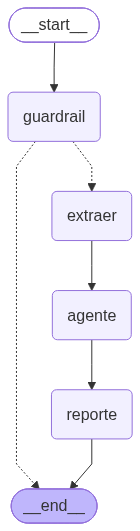

In [ ]:
# 3.2 · Dibujo del workflow (no editar)
try:
    from IPython.display import Image, display
    display(Image(construir_workflow(componentes, {}).get_graph().draw_mermaid_png()))
except Exception:
    print(construir_workflow(componentes, {}).get_graph().draw_mermaid())

## 4 · Pruebas y evidencia (no editar)

In [ ]:
# 4.1 · Ejecuta los casos y registra la evidencia (no editar)
import json
import time
import pandas as pd

def describir(r: dict) -> str:
    if r is None:
        return ""
    resumen = {
        "estado": r["estado_final"], "razon": r["razon"], "prob_clinico": r["prob_clinico"],
        "codigos": [c["codigo"] for c in r["candidatos"]], "rondas_agente": r["rondas_agente"],
        "latencias_s": r["latencias"], "advertencias": r["advertencias"],
    }
    return json.dumps(resumen, ensure_ascii=False)

def rondas_de(observado: str):
    return json.loads(observado)["rondas_agente"] if observado else None

async def correr_casos(casos, componentes):
    filas = []
    for caso in casos:
        print(f"→ {caso['id']} · {caso['tipo']}")
        inicio = time.perf_counter()
        resultado, error = None, ""
        try:
            resultado = await ejecutar(caso["entrada"], componentes)
        except Exception as exc:
            error = f"{type(exc).__name__}: {exc}"
        latencia = round(time.perf_counter() - inicio, 2)
        try:
            paso = resultado is not None and bool(caso["verificar"](resultado))
        except Exception as exc:
            paso, error = False, error or f"Error al verificar: {exc}"
        filas.append({
            "template": TEMPLATE_ID, "id": caso["id"], "tipo": caso["tipo"], "entrada": caso["entrada"],
            "esperado": caso["esperado"], "criterio": caso["criterio"], "observado": describir(resultado),
            "veredicto_auto": "PASS" if paso else "FAIL", "veredicto_final": "",
            "latencia_s": latencia, "error": error,
        })
    return pd.DataFrame(filas)

registro = await correr_casos(CASOS, componentes)
pd.set_option("display.max_colwidth", 220)
vista = registro.assign(rondas=registro["observado"].map(rondas_de))
display(vista[["id", "tipo", "veredicto_auto", "rondas", "latencia_s", "observado", "error"]])
print(f"\nResultado automático: {(registro.veredicto_auto == 'PASS').sum()} de {len(registro)} casos en PASS")

→ P1 · caso completo
→ P2 · datos ausentes
→ P3 · fuera de contexto
→ P4 · instrucciones inyectadas


Salida con formato inválido: reintento 1 de 2


,id,tipo,veredicto_auto,rondas,latencia_s,observado,error
0,P1,caso completo,PASS,2,49.72,"{""estado"": ""ok"", ""razon"": """", ""prob_clinico"": 0.9617064, ""codigos"": [""6A70.1"", ""6A70.Z"", ""6A72"", ""6B43""], ""rondas_agente"": 2, ""latencias_s"": {""anonimizar"": 0.8, ""guardrail"": 15.809, ""extraer"": 2.677, ""agente"": 20.025...",
1,P2,datos ausentes,PASS,2,38.54,"{""estado"": ""ok"", ""razon"": """", ""prob_clinico"": 0.95884305, ""codigos"": [""6A70.5"", ""6A72"", ""7A00"", ""7A01"", ""6E62.0""], ""rondas_agente"": 2, ""latencias_s"": {""anonimizar"": 1.037, ""guardrail"": 0.37, ""extraer"": 2.551, ""agente...",
2,P3,fuera de contexto,PASS,0,12.65,"{""estado"": ""fuera_de_alcance"", ""razon"": ""Probabilidad de contexto clínico 0.014724707 por debajo del umbral 0.5"", ""prob_clinico"": 0.014724707, ""codigos"": [], ""rondas_agente"": 0, ""latencias_s"": {""anonimizar"": 11.639, ...",
3,P4,instrucciones inyectadas,PASS,2,67.74,"{""estado"": ""ok"", ""razon"": """", ""prob_clinico"": 0.88593197, ""codigos"": [""6A70.5"", ""6A70.Z"", ""6A70.1""], ""rondas_agente"": 2, ""latencias_s"": {""anonimizar"": 3.89, ""guardrail"": 22.368, ""extraer"": 2.397, ""agente"": 22.243, ""r...",



Resultado automático: 4 de 4 casos en PASS


In [ ]:
# 4.2 · Guarda el registro de pruebas (no editar)
archivo = f"registro_pruebas_{TEMPLATE_ID}.csv"
registro.to_csv(archivo, index=False, encoding="utf-8-sig")
print("Registro guardado:", archivo)

Registro guardado: registro_pruebas_LC-B+C.csv


In [ ]:
# 4.3 · Falla de conexión al MCP: el flujo debe detenerse sin reporte (no editar)
from poc_psico.agente import cargar_tools
from poc_psico.errores import FlujoDetenido

async def _agente_roto(sintomas):
    await cargar_tools("https://no-existe.invalid/sse", TOOLS_PERMITIDAS)

roto = Componentes(ner=ner_es, guardrail=_guardrail, extraer=crear_extractor(llm), agente=_agente_roto,
                   redactar=crear_redactor(llm), umbral=UMBRAL_GUARDRAIL)
r = await ejecutar(CASOS[0]["entrada"], roto)
assert r["estado_final"] == "error" and r["reporte_md"] == "", r
print("OK, se detuvo con:", r["razon"])

OK, se detuvo con: No se pudo conectar al MCP CIE-11 (https://no-existe.invalid/sse): unhandled errors in a TaskGroup (1 sub-exception)


## 5 · Prueba libre y reporte

In [ ]:
# 5 · Prueba libre: escribe tu viñeta sintética
entrada = "Paciente de 41 años con ánimo irritable, preocupación constante y tensión muscular desde hace 8 meses."
r = await ejecutar(entrada, componentes)
print(r["estado_final"], "|", r["razon"])
from IPython.display import Markdown
Markdown(r["reporte_md"]) if r["reporte_md"] else None

ok | 


# Reporte de apoyo al psicodiagnóstico

## 1. Datos del caso

- Paciente: No identificado

- Edad: 41

- Sexo: No indicado

- Temporalidad: desde hace 8 meses

- Fecha del reporte: 2026-10-14

## 2. Síntomas por categoría

### Cognitivos

- Ninguno identificado

### Emocionales

- Ánimo irritable
- Preocupación constante

### Conductuales

- Tensión muscular

### Afectación social

- Ninguno identificado

## 3. Hipótesis diagnósticas (de la más a la menos plausible)

### 1. Trastorno de ansiedad generalizada — `6B00`

[Abrir en el navegador OMS](https://icd.who.int/browse/2026-01/mms/es#1712535455)

**Justificación:** Preocupación constante, irritabilidad y tensión muscular persistentes durante 8 meses encajan con el núcleo de la ansiedad generalizada, que exige varios meses de síntomas de ansiedad y preocupación excesiva sobre múltiples eventos cotidianos. La definición menciona además irritabilidad, dificultad de concentración y alteraciones del sueño como síntomas acompañantes, y la duración supera el mínimo exigido.

**Criterios cumplidos:**

- Duración de varios meses (8 meses)
- Preocupación constante
- Tensión muscular
- Irritabilidad

**Criterios no cumplidos o sin confirmar:**

- Preocupación centrada en múltiples eventos cotidianos (temas no especificados)
- Deterioro o angustia significativa en áreas de funcionamiento (no documentado)
- Severidad no registrada
- Concentración y sueño no evaluados
- Ausencia de sustancias o condición médica que lo explique (no evaluado)

### 2. Trastorno de adaptación — `6B43`

[Abrir en el navegador OMS](https://icd.who.int/browse/2026-01/mms/es#264310751)

**Justificación:** Si la preocupación y la irritabilidad se relacionan con un estresante psicosocial identificable, podría tratarse de una reacción de adaptación. Esta hipótesis queda como alternativa, aunque es menos compatible porque no hay estresor registrado y la duración de 8 meses supera el marco habitual de 6 meses salvo que el estresante persista.

**Criterios cumplidos:**

- Preocupación excesiva y persistente
- Síntomas emocionales tras un posible estresor (por confirmar)

**Criterios no cumplidos o sin confirmar:**

- Estresante psicosocial identificable (no registrado)
- Inicio dentro del mes del estresante (no evaluado)
- Duración compatible con resolución en 6 meses (no cumple salvo que el estresante persista)

### 3. Trastorno mixto de depresión y ansiedad — `6A73`

[Abrir en el navegador OMS](https://icd.who.int/browse/2026-01/mms/es#314468192)

**Justificación:** Combina síntomas de ansiedad (preocupación, tensión muscular, irritabilidad) con posible afectación del ánimo. Se mantiene como opción solo si aparecen síntomas depresivos, que hoy no están reportados.

**Criterios cumplidos:**

- Síntomas de ansiedad: preocupación, tensión muscular, irritabilidad
- Duración superior a dos semanas

**Criterios no cumplidos o sin confirmar:**

- Estado de ánimo deprimido o anhedonia (no reportados)
- Ausencia de antecedentes de episodios maníacos o mixtos (no evaluado)
- Ningún conjunto de síntomas suficiente por separado (no evaluado)

### Ambigüedades

- El caso no especifica el contenido de la preocupación ni si es multitemática
- No consta si existe deterioro funcional ni severidad
- Duración de 8 meses no coincide con el marco de un trastorno de adaptación sin estresor claro
- La irritabilidad podría ser un síntoma aislado o un rasgo del ánimo
- Las notas del agente mencionan 3 de 5 rondas de búsqueda; el caso no aporta sustancias ni antecedentes médicos

## 4. Diferenciales y exclusiones

- Trastorno de adaptación (6B43) si existe un estresante identificable
- Trastorno mixto de depresión y ansiedad (6A73) si aparecen síntomas depresivos
- Trastorno de pánico (6B01), a descartar por ausencia de crisis reportadas
- Trastorno de ansiedad inducido por sustancias o medicamentos (6C4x.71), a descartar con historia de consumo
- Ansiedad secundaria a condición médica (6E63 u otra causa orgánica), a descartar con evaluación médica
- Trastorno depresivo recurrente o episodio único, a descartar si hay ánimo deprimido persistente
- Ansiedad en demencia (6D86.2), poco probable a los 41 años
- Trastornos de ansiedad no especificados (6B0Z) como categoría residual si no se confirman criterios

### Alternativas consultadas y descartadas

- Trastornos específicamente asociados con el estrés, sin especificación (`6B4Z`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#unspecified)

- Mutismo selectivo (`6B06`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#167946871)

- Trastornos mentales o del comportamiento asociados con el embarazo, el parto o el puerperio, sin síntomas psicóticos [Trastorno de adaptación] (`6E20/6B43`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#264310751)

- Nerviosismo (`MB24.3`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#2027043655)

- Crisis de ansiedad (`MB23.H`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#1707067746)

- Síndrome de ansiedad secundario (`6E63`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#2131412196)

- Hipocondriasis, sin especificación (`6B23.Z`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#unspecified)

- Trastorno de ansiedad social (`6B04`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#2062286624)

- Trastorno de ansiedad por separación (`6B05`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#830200631)

- Trastornos de ansiedad o relacionados con el miedo, sin especificación (`6B0Z`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#unspecified)

## 5. Datos faltantes por recabar

- sexo del paciente
- severidad de los síntomas
- impacto funcional en trabajo, familia o relaciones
- contenido y número de áreas de la preocupación
- síntomas cognitivos (concentración, memoria)
- calidad del sueño
- antecedentes psiquiátricos y personales
- antecedentes médicos y condiciones de salud que puedan causar los síntomas
- consumo de sustancias, cafeína y medicamentos
- factores desencadenantes o eventos estresantes y su fecha de inicio
- síntomas depresivos (ánimo, anhedonia) y antecedentes de episodios maníacos o mixtos
- presencia de ideación suicida
- síntomas autonómicos (palpitaciones, sudoración, disnea) y presencia de crisis de pánico

## 6. Pruebas complementarias sugeridas

> Sugerencias a validar por el profesional. Solo se indica el nombre de la prueba: no se incluyen cuestionarios ni formas de calificación.

- **Entrevista clínica estructurada para trastornos de ansiedad (SCID-5-CV, módulo de ansiedad)**: Permite verificar de forma sistemática los criterios de ansiedad generalizada, la duración y el deterioro funcional.

- **Inventario de Ansiedad de Beck**: Ofrece una medida de la severidad de los síntomas ansiosos somáticos y cognitivos para seguimiento.

- **Inventario de Depresión de Beck**: Ayuda a descartar o confirmar síntomas depresivos que diferenciarían del trastorno mixto.

- **Cuestionario de Preocupación de Pensilvania**: Caracteriza la preocupación excesiva y su grado de incontrolabilidad, aspecto central del diagnóstico.

- **Índice de Calidad del Sueño de Pittsburgh**: Evalúa la calidad del sueño, síntoma asociado que la definición menciona y que el caso no documenta.

## 7. Aviso

Este reporte contiene hipótesis de apoyo generadas con ayuda de IA a partir de la CIE-11. No es un diagnóstico: la decisión clínica es del profesional.


In [ ]:
# 5.1 · Prueba con foto de una nota manuscrita (motor en OCR_MOTOR, celda 2.1; ver README)
RUTA_FOTO = "data/caso1_m_28.jpeg"  # EDITA AQUÍ: ruta a tu foto .jpg o .png; déjalo vacío para omitir
from IPython.display import Markdown

r = await ejecutar(RUTA_FOTO, componentes)
print("Texto leído (revísalo: un error de lectura cambia el sentido clínico):\n", r["texto_ocr"])
print(r["estado_final"], "|", r["razon"], "|", r["latencias"])
Markdown(r["reporte_md"]) if r["reporte_md"] else None

Texto leído (revísalo: un error de lectura cambia el sentido clínico):
 LUCTA 28 AÑOS

Vive con sus padres
Tiene 3 hermanos mayores

Refiere ansiedad al
estar en situaciones donde
hay mucha gente

Le cuesta trabajo hablam
con desconocidos. Refiere
que nosasiente escuchada en
casa y nunca ha creído
tener un lugar para poder
dar su opinión.

Terminó con su novio
hace 2 meses y desde eso
menos quiere salir de
casa e interactuar.
Hay días que tampoco
quiere levantarse en la
trabajo y que les fue
sólo duerme.
ok |  | {'ocr': 4.133, 'anonimizar': 1.462, 'guardrail': 22.403, 'extraer': 3.77, 'agente': 18.124, 'reporte': 10.022}


# Reporte de apoyo al psicodiagnóstico

## 1. Datos del caso

- Paciente: LU

- Edad: 28

- Sexo: No indicado

- Temporalidad: "Ruptura de noviazgo hace 2 meses; el retraimiento social y los días sin querer levantarse comenzaron después de esa ruptura"

- Fecha del reporte: 2026-10-14

## 2. Síntomas por categoría

### Cognitivos

- Ninguno identificado

### Emocionales

- Ansiedad en situaciones con mucha gente
- Sensación de no ser escuchada en casa
- Sensación de no tener un lugar para dar su opinión

### Conductuales

- Dificultad para hablar con desconocidos
- Menos ganas de salir de casa e interactuar
- Días sin querer levantarse de la cama
- Días en que solo duerme

### Afectación social

- Vive con sus padres y tiene 3 hermanos mayores
- Disminución de la interacción social tras ruptura de pareja
- Dificultad para interactuar con desconocidos

## 3. Hipótesis diagnósticas (de la más a la menos plausible)

### 1. Trastorno de adaptación — `6B43`

[Abrir en el navegador OMS](https://icd.who.int/browse/2026-01/mms/es#264310751)

**Justificación:** Inicio de retraimiento social, días sin querer levantarse y dificultad para interactuar tras la ruptura de noviazgo hace 2 meses, lo que encaja temporalmente con un estresante psicosocial identificable que surge dentro del primer mes. Los síntomas describen una reacción desadaptativa con cavilación sobre la ruptura, aunque el texto no la documenta explícitamente.

**Criterios cumplidos:**

- Estresante psicosocial identificable (ruptura de noviazgo)
- Inicio de síntomas tras el estresante
- Deterioro en la vida social (disminución de interacción social)
- Retraimiento y menos ganas de salir de casa

**Criterios no cumplidos o sin confirmar:**

- Preocupación o cavilación constante sobre la ruptura no documentada
- Duración: se resuelve en 6 meses salvo persistencia del estresante, por evaluar
- Deterioro en trabajo o estudios no documentado
- Exclusión de trastorno del estado de ánimo pendiente de confirmar (ánimo y anhedonia faltan)

### 2. Trastorno de ansiedad social — `6B04`

[Abrir en el navegador OMS](https://icd.who.int/browse/2026-01/mms/es#2062286624)

**Justificación:** La ansiedad en situaciones con mucha gente y la dificultad para hablar con desconocidos corresponden al miedo a situaciones sociales y a su evitación, que son el núcleo de este trastorno. El retraimiento social podría reflejar evitación de estas situaciones.

**Criterios cumplidos:**

- Miedo o ansiedad ante situaciones sociales (multitudes, desconocidos)
- Dificultad para hablar con desconocidos
- Evitación social: menos ganas de salir e interactuar

**Criterios no cumplidos o sin confirmar:**

- Persistencia durante al menos varios meses no documentada; el inicio parece posterior a la ruptura hace 2 meses
- Preocupación por ser evaluada negativamente no explorada
- Grado de deterioro significativo no documentado
- Ausencia de otro trastorno que explique mejor los síntomas no evaluada

### 3. Trastorno depresivo de episodio único, sin especificación — `6A70.Z`

[Abrir en el navegador OMS](https://icd.who.int/browse/2026-01/mms/es#unspecified)

**Justificación:** Los días sin querer levantarse, el retraimiento y los días en que solo duerme podrían corresponder a un episodio depresivo de episodio único. Sin embargo, no hay datos de estado de ánimo, anhedonia ni duración suficientes para sostener este diagnóstico, por lo que queda como hipótesis a descartar.

**Criterios cumplidos:**

- Cambios conductuales de retraimiento y pérdida de energía para levantarse
- Alteración del sueño (días en que solo duerme)

**Criterios no cumplidos o sin confirmar:**

- Estado de ánimo deprimido no documentado
- Anhedonia no documentada
- Número de síntomas, duración de al menos 2 semanas y deterioro no confirmados
- Severidad no documentada

### Ambigüedades

- El retraimiento y los días sin levantarse pueden ser reacción a la ruptura o síntomas depresivos
- No se sabe si la ansiedad en multitudes es previa a la ruptura o surgió después
- El texto habla de dormir solo en días sin levantarse; la cantidad y calidad del sueño no están claras
- La sensación de no ser escuchada en casa podría ser un conflicto familiar o un estresante adicional
- No se sabe si el malestar en multitudes está presente en todos los contextos sociales o solo en algunos

## 4. Diferenciales y exclusiones

- Trastorno depresivo de episodio único (6A70.Z) según ánimo, anhedonia y duración
- Trastorno de ansiedad social (6B04) si la ansiedad es persistente y previa o independiente de la ruptura
- Trastorno de adaptación (6B43) como explicación más directa del inicio tras la ruptura, con exclusión de trastornos depresivos
- Trastorno depresivo recurrente: descartar antecedentes de episodios previos
- Trastornos del estado de ánimo bipolares: descartar episodios de manía o hipomanía
- Trastornos psicóticos: no hay síntomas psicóticos descritos
- Efectos del consumo de sustancias o alcohol sobre ánimo y sueño: no explorado
- Trastorno por duelo prolongado: aplicable si la ruptura se vive como pérdida significativa; exclusión en 6B43
- Mutismo selectivo (6B06): descartado por ser aplicable a la infancia

### Alternativas consultadas y descartadas

- Trastorno depresivo de episodio único, moderado, sin síntomas psicóticos (`6A70.1`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#399670840)

- Otro trastorno depresivo de episodio único, especificado (`6A70.Y`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#other)

- Trastorno depresivo recurrente, sin especificación (`6A71.Z`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#unspecified)

- Episodio depresivo actual persistente (`6A80.2`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#1906190365)

- Episodio depresivo actual con melancolía (`6A80.3`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#802537726)

- Trastorno depresivo, episodio único grave sin síntomas psicóticos (`6A70.3`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#1669279433)

- Trastorno depresivo de episodio único, leve (`6A70.0`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#1922675618)

- Trastorno depresivo, episodio único de gravedad no especificada (`6A70.5`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#554273362)

- Otro síndrome vestibular episódico especificado (`AB31.Y`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#other)

- Trastorno depresivo recurrente, episodio actual, gravedad no especificada (`6A71.5`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#1905765233)

## 5. Datos faltantes por recabar

- Estado de ánimo general y presencia de tristeza
- Anhedonia
- Severidad de los síntomas
- Duración e inicio de la ansiedad en multitudes
- Ideación suicida
- Sueño: cantidad y calidad
- Apetito y peso
- Energía y concentración
- Impacto en el trabajo o estudios (faltas, rendimiento)
- Consumo de sustancias
- Antecedentes psiquiátricos personales y familiares
- Tratamientos previos
- Relación actual con la familia y red de apoyo
- Sexo de la paciente
- Preocupación o cavilación sobre la ruptura
- Duración total de los síntomas (6 meses frente a 2 meses)
- Antecedentes de episodios depresivos o maníacos previos

## 6. Pruebas complementarias sugeridas

> Sugerencias a validar por el profesional. Solo se indica el nombre de la prueba: no se incluyen cuestionarios ni formas de calificación.

- **Entrevista clínica estructurada para trastornos del DSM-5 (SCID-5)**: Permite explorar sistemáticamente episodios del ánimo, ansiedad social y trastornos relacionados con el estresante para diferenciar los diagnósticos candidatos.

- **Escala de Ansiedad Social de Liebowitz**: Cuantifica el miedo y la evitación en situaciones sociales concretas, útil para valorar la gravedad de la ansiedad en multitudes.

- **Inventario de Depresión de Beck-II**: Valora la intensidad de los síntomas depresivos, incluyendo ánimo, energía y sueño, para apoyar o descartar un episodio depresivo.

- **Escala de Evaluación de Estrés Postraumático o de Ajuste (Escala de Impacto de Eventos Revisada)**: Ayuda a evaluar la preocupación y la cavilación sobre la ruptura como estresante, relevantes para el trastorno de adaptación.

## 7. Aviso

Este reporte contiene hipótesis de apoyo generadas con ayuda de IA a partir de la CIE-11. No es un diagnóstico: la decisión clínica es del profesional.


## 6 · Cierre del PoC
Completa esta celda antes de entregar (doble clic para editar).

- **Hipótesis evaluada:**
- **Resultado:** _ de 4 casos en PASS, con veredicto revisado.
- **Evidencia principal:** (rondas del agente, latencias, códigos obtenidos)
- **Guardrail:** Decisions API o plan B con LLM, y por qué.
- **Limitación principal:**
- **Decisión:** continuar / ajustar / descartar.